# XNLI exploratory data analysis

**The task:** given a *premise* and a *hypothesis*, predict whether they are `entailment`, `contradiction` or `neutral`.

| Split | File | Where the text comes from | Rows per language | What it's for |
|---|---|---|---|---|
| **Train** | `XNLI-MT-1.0/multinli/multinli.train.{lang}.tsv` | English is the original MultiNLI; the other 14 languages are **machine translated** | 392,702 | Updating the model weights |
| **Validation (dev)** | `XNLI-1.0/xnli.dev.tsv` | Written in English, **translated by professionals** | 2,490 | Choosing the best checkpoint and hyperparameters |
| **Test** | `XNLI-1.0/xnli.test.tsv` | Same as dev | 5,010 | Reporting the final score only |

- Each train file holds one language. The dev and test files hold all 15, marked by a `language` column.
- `XNLI-MT-1.0/xnli/` isn't used in this project. It holds dev and test machine-translated *into English*, for a baseline from the XNLI paper.
- The `.jsonl` files hold the same dev and test data as the `.tsv` files.

In [1]:
import csv

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import GPT2TokenizerFast

LANGS = ["en", "ar", "bg", "de", "el", "es", "fr", "hi", "ru", "sw", "th", "tr", "ur", "vi", "zh"]

def read_tsv(path):
    return pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str, keep_default_na=False)

train = {lang: read_tsv(f"XNLI-MT-1.0/multinli/multinli.train.{lang}.tsv") for lang in LANGS}
dev = read_tsv("XNLI-1.0/xnli.dev.tsv")
test = read_tsv("XNLI-1.0/xnli.test.tsv")

/home/long/miniconda3/envs/critnet_hai/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Size and columns
Every language has the same number of rows in every split. Train has only 3 columns, while dev and test have 19. The project uses just `sentence1` (premise), `sentence2` (hypothesis) and `gold_label`.

In [2]:
sizes = pd.DataFrame({
    "train": {lang: len(train[lang]) for lang in LANGS},
    "dev": dev["language"].value_counts(),
    "test": test["language"].value_counts(),
}).loc[LANGS]
print("Train columns:", list(train["en"].columns))
print("Dev/test columns:", list(dev.columns))
sizes

Train columns: ['premise', 'hypo', 'label']
Dev/test columns: ['language', 'gold_label', 'sentence1_binary_parse', 'sentence2_binary_parse', 'sentence1_parse', 'sentence2_parse', 'sentence1', 'sentence2', 'promptID', 'pairID', 'genre', 'label1', 'label2', 'label3', 'label4', 'label5', 'sentence1_tokenized', 'sentence2_tokenized', 'match']


,train,dev,test
en,392702,2490,5010
ar,392702,2490,5010
bg,392702,2490,5010
de,392702,2490,5010
el,392702,2490,5010
es,392702,2490,5010
fr,392702,2490,5010
hi,392702,2490,5010
ru,392702,2490,5010
sw,392702,2490,5010


## 2. Labels
The three labels are almost perfectly balanced, so random guessing scores about 33%. Train says `contradictory` where dev and test say `contradiction`; `XNLIDataset` already handles this.

In [9]:
pd.DataFrame({
    "train": train["en"]["label"].replace({"contradictory": "contradiction"}).value_counts(),
    "dev": dev.loc[dev["language"] == "en", "gold_label"].value_counts(),
    "test": test.loc[test["language"] == "en", "gold_label"].value_counts(),
})

,train,dev,test
contradiction,130903,830,1670
entailment,130899,830,1670
neutral,130900,830,1670


## 3. The same examples in every language
The languages are parallel: row *i* of every train file is the same example, and dev and test link translations through `pairID`. Labels match across languages, apart from 2 Russian test rows, so comparing languages compares the same questions.

In [18]:
i = 100
j = 100

In [24]:
for lang in ["en", "fr", "zh"]:
    row = train[lang].iloc[i]
    print(f"train {lang}: {row['premise']} | {row['hypo']} | {row['label']}")
print()
for lang in ["en", "fr", "zh"]:
    row = dev[(dev["pairID"] == f"{j}") & (dev["language"] == lang)].iloc[0]
    print(f"dev   {lang}: {row['sentence1']} | {row['sentence2']} | {row['gold_label']}")

print("\nTrain labels identical across languages:",
      all((train[lang]["label"] == train["en"]["label"]).all() for lang in LANGS))
for name, split in [("Dev", dev), ("Test", test)]:
    en_labels = split[split["language"] == "en"].set_index("pairID")["gold_label"]
    differs = split["gold_label"] != split["pairID"].map(en_labels)
    print(f"{name} rows whose label differs from English:", split.loc[differs, "language"].value_counts().to_dict())

train en: It displays all kinds of vehicles , from the coach that carried Napoleon to and from Moscow in 1812 to a splendid 4-horsepower Renault car from 1904 and other turn-of-the-century classics . | The exhibition only displays cars from the 2000s . | contradictory
train fr: Il affiche toutes sortes de véhicules , de l' entraîneur qui a transporté Napoléon à et de Moscou en 1812 à une splendide voiture RENAULT 4 chevaux à partir de 1904 et d' autres classiques du début du siècle . | L' exposition n' affiche que des voitures des années 2000 | contradictory
train zh: 从 1812年 带 拿破仑 到 莫斯科 的 教练 , 从 1904年 到 1904年 的 一 辆 优秀 的 4 马力 雷诺 车 , 以及 其他 世纪 的 经典 , 展示 了 各种各样 的 车辆 . | 展览 只 显示 2000年 代 的 汽车 . | contradictory

dev   en: When I pull, when he pulls the canopy for me to start getting him out, he points to two instruments on the left side of the aircraft that had actually melted during the flight. | All of the instruments in the aircraft were intact. | contradiction
dev   fr: Lorsque je tire, 

## 4. Premises are reused
Almost every premise appears three times, once per label, so a model can't rely on the premise alone. Any new split must keep a premise's rows together.

In [5]:
en_dev = dev[dev["language"] == "en"]
en_test = test[test["language"] == "en"]
for name, premises in [("train", train["en"]["premise"]), ("dev", en_dev["sentence1"]), ("test", en_test["sentence1"])]:
    print(f"{name:5} {len(premises):>7,} rows | {premises.nunique():>7,} unique premises | {len(premises) / premises.nunique():.2f} rows per premise")
per_premise = train["en"].groupby("premise")["label"].agg(["size", "nunique"])
print(f"Train premises with exactly 3 rows and 3 different labels: {((per_premise['size'] == 3) & (per_premise['nunique'] == 3)).mean():.1%}")
print("Genres in dev:", en_dev["genre"].nunique(), "| train files have no genre column")

train 392,702 rows | 128,094 unique premises | 3.07 rows per premise
dev     2,490 rows |     830 unique premises | 3.00 rows per premise
test    5,010 rows |   1,670 unique premises | 3.00 rows per premise


Train premises with exactly 3 rows and 3 different labels: 98.2%
Genres in dev: 10 | train files have no genre column


## 5. Train text is tokenized, dev and test are not
Train has spaces around punctuation (`didn 't know ,`). Dev and test `sentence1` is natural text. For Chinese and Thai, train also has spaces between words, while real text in those languages mostly has none.

In [6]:
premises = train["en"]["premise"]
print("train en:", premises[premises.str.contains(" 't ") & premises.str.contains(" , ")].iloc[0][:90])
print("dev en:  ", en_dev["sentence1"].iloc[3][:90])

def spaces_per_100_chars(text):
    return 100 * text.str.count(" ").sum() / text.str.len().sum()

pd.DataFrame({
    "train": {lang: spaces_per_100_chars(train[lang]["premise"]) for lang in ["en", "zh", "th"]},
    "dev": {lang: spaces_per_100_chars(dev.loc[dev["language"] == lang, "sentence1"]) for lang in ["en", "zh", "th"]},
}).round(1)

train en: I don 't mean to be glib about your concerns , but if I were you , I might be more concern
dev en:   I didn't know what I was going for or anything, so was to report to a designated place in 


,train,dev
en,18.3,16.4
zh,37.0,1.0
th,20.6,2.9


## 6. Data quality
The last 2,000 Arabic train rows have an empty hypothesis but still carry a label. Duplicates are too few to matter.

In [7]:
quality = pd.DataFrame({
    "empty_premise": {lang: (train[lang]["premise"].str.strip() == "").sum() for lang in LANGS},
    "empty_hypothesis": {lang: (train[lang]["hypo"].str.strip() == "").sum() for lang in LANGS},
    "duplicate_rows": {lang: train[lang].duplicated().sum() for lang in LANGS},
})
empty_rows = train["ar"].index[train["ar"]["hypo"].str.strip() == ""]
print(f"Arabic empty hypotheses: rows {empty_rows.min():,} to {empty_rows.max():,}")
quality

Arabic empty hypotheses: rows 390,702 to 392,701


,empty_premise,empty_hypothesis,duplicate_rows
en,0,0,28
ar,0,2000,83
bg,0,0,102
de,0,0,70
el,0,0,131
es,0,0,88
fr,0,0,128
hi,0,0,68
ru,0,0,104
sw,0,0,61


## 7. Prompt length in GPT-2 tokens
This measures each training prompt in the exact format the model sees, on a random sample of 20,000 rows per language. GPT-2's tokenizer was built for English, so other scripts need far more tokens for the same content.

In [8]:
tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
tokenizer.model_max_length = 10**6  # we are only counting tokens here

rows = {}
for lang in LANGS:
    sample = train[lang].sample(20_000, random_state=0)
    prompts = [f"Premise: {p}\nHypothesis: {h}\nLabel:" for p, h in zip(sample["premise"], sample["hypo"])]
    lengths = np.array([len(ids) for ids in tokenizer(prompts)["input_ids"]])
    rows[lang] = {"median": np.median(lengths), "p99": np.percentile(lengths, 99),
                  "max": lengths.max(), "pct_over_1024": 100 * (lengths > 1024).mean()}

lengths_df = pd.DataFrame(rows).T.sort_values("median").round(2)
lengths_df["vs_en"] = (lengths_df["median"] / lengths_df.loc["en", "median"]).round(1)
lengths_df

,median,p99,max,pct_over_1024,vs_en
en,45.0,108.00,343.0,0.00,1.0
sw,68.0,177.01,551.0,0.00,1.5
es,70.0,182.00,587.0,0.00,1.6
fr,72.0,187.01,595.0,0.00,1.6
tr,78.0,201.00,500.0,0.00,1.7
de,78.0,207.00,698.0,0.00,1.7
zh,122.0,324.01,1167.0,0.00,2.7
ar,140.0,381.01,1177.0,0.01,3.1
vi,159.0,430.00,1537.0,0.01,3.5
ur,170.0,444.00,1197.0,0.01,3.8


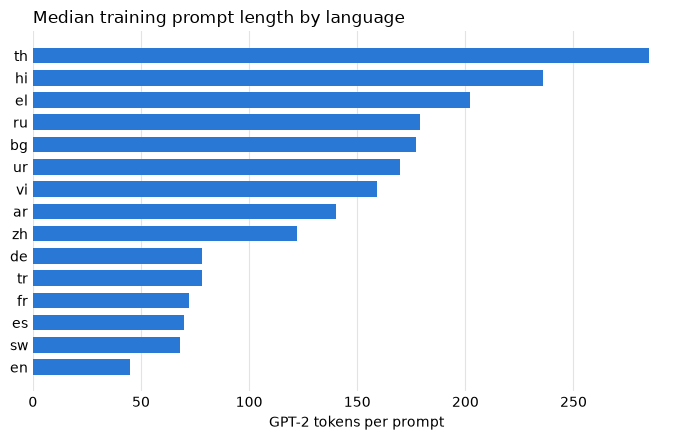

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(lengths_df.index, lengths_df["median"], height=0.7, color="#2a78d6")
ax.set_title("Median training prompt length by language", loc="left", fontsize=12)
ax.set_xlabel("GPT-2 tokens per prompt")
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## What this means for the project
- **Keep test for the end.** Use dev to compare runs, and test only for the final numbers.
- **Drop the 2,000 empty Arabic rows before training on Arabic.** `dropna` in `XNLIDataset` misses them because they are empty strings, not missing values.
- **Train and evaluation text look different.** English differs only in punctuation spacing. `XNLIDataset` removes all spaces for Chinese but not for Thai, so Thai train text stays word-separated while its dev and test text mostly isn't.
- **Thai and Hindi cost the most.** Their prompts are about 6.3x and 5.2x longer than English, so they train slower. A small share also exceeds GPT-2's 1,024-token limit (0.33% for Thai, 0.13% for Hindi), and those rows lose their label when truncated.
- **Machine translation adds noise.** Non-English train labels are copied from English, so a poorly translated pair may no longer fit its label. Dev and test were translated by people, so they don't have this problem.